# Lista 1

**Aluno:** Antônio Rodrigo Lima de Andrade Tenório
\
**Nome da base:** creditcard.csv

## Orientações

- Escolha apenas uma das bases disponíveis e resolva todas as 10 questões usando essa mesma base.
- Desenvolva toda a atividade em Python, no formato de entrega do Google Colab.
- Organize o notebook por questão, com códigos executáveis, saídas geradas e comentários objetivos.
- Não troque de base ao longo da atividade.
- Não faça tratamento manual linha por linha.
- Sempre que necessário, sustente suas decisões com tabelas, métricas, gráficos e resultados do código.

## Importação das bibliotecas

In [23]:
# Bibliotecas principais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
warnings.filterwarnings('ignore')

# Pré-processamento e modelagem
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.under_sampling import RandomUnderSampler

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## Carregamento da base

In [24]:
# Carregamento da base
# Substitua o nome do arquivo pelo arquivo correto da base escolhida
df = pd.read_csv('creditcard.csv')

# Visualização inicial
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Questão 1 – Diagnóstico estrutural

**Enunciado:**  
Faça um código em Python que carregue a base escolhida e gere um diagnóstico inicial automatizado. Mostre dimensões da base, tipos de dados, valores ausentes, duplicidades, cardinalidade das colunas e possíveis inconsistências de leitura. Em seguida, defina qual será o problema computacional tratado no cenário escolhido, deixando claro se a tarefa será de classificação, regressão ou segmentação. Organize essa etapa em uma função reutilizável.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Primeiro passo foi o entendimento da base de dados, pesquisar sobre ela, e enteder sobre o que se trata (Transções fraudulentas)
- Depois disso foi vizualizar o tamanho da tabela, tipo de dadsos, valores ausentes, se tem valores únicos por coluna e possíveis inconstancias

### Desenvolvimento
Implemente abaixo o código da questão.

In [25]:
# Código da Questão 1
def gerar_diagnostico(df):

    print(f"dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas.")

    print("\ntipos dos dados:")
    print(df.dtypes)

    print("\nvalores ausentes:")
    print(df.isnull().sum())

    print(f"\nlinhas duplicadas: {df.duplicated().sum()}")

    print("\ncardinalidade (valores únicos por coluna):")
    print(df.nunique())

    print("\npossíveis inconsistências:")
    # Verifica se existem colunas com apenas 1 valor
    colunas_constantes = [col for col in df.columns if df[col].nunique() <= 1]
    if colunas_constantes:
        print(f"- colunas com valores únicos: {colunas_constantes}")
    else:
        print("- nenhuma coluna constante detectada.")

# DEFINIÇÃO DO PROBLEMA:
# O objetivo é analisar transações de cartão de crédito para identificar padrões de uso.
# Vamos utilizar uma tarefa de CLASSIFICAÇÃO para prever se uma transação é fraudulenta ou não.
gerar_diagnostico(df)

dimensões: 284807 linhas e 31 colunas.

tipos dos dados:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

valores ausentes:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amou

### Conclusão da Questão 1
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

A análise inicial revela que a base de dados possui uma estrutura robusta, composta majoritariamente por variáveis numéricas resultantes de uma transformação PCA, o que garante a privacidade dos dados sensíveis, mas exige uma análise puramente estatística.

Principais pontos observados:

- Integridade Estrutural: A ausência de valores nulos facilita o início do processamento, permitindo focar diretamente na modelagem.

- Tarefa Computacional: O problema foi definido como uma Classificação Binária, pois o objetivo central é rotular transações entre duas categorias discretas: Legítimas (0) ou Fraudulentas (1).

- Desafio de Escala: A alta cardinalidade das variáveis e a diferença de escala entre as colunas V e a coluna Amount indicam a necessidade futura de normalização para que o modelo não seja tendencioso.

## Questão 2 – Auditoria de qualidade

**Enunciado:**  
Faça um código em Python para auditar a qualidade dos dados. Identifique valores implausíveis, colunas com tipos inadequados, categorias raras, padrões suspeitos de preenchimento, possíveis outliers e inconsistências importantes para o cenário escolhido. Se houver datas, verifique coerência temporal. Se houver valores monetários, verifique compatibilidade entre grandezas. Ao final, apresente um resumo dos principais problemas encontrados.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

1. Integridade: Verificamos a ausência de valores negativos e se a coluna Time segue ordem cronológica (monotônica).

2. Outliers: Aplicamos o método IQR com multiplicador 3 para capturar apenas anomalias extremas, justificável pela disparidade de 290x encontrada no Amount.

3. Qualidade Técnica: Auditamos valores nulos, tipagem (100% numérica) e padrões suspeitos de preenchimento (transações idênticas no mesmo tempo).

4. Diagnóstico de Classe: Identificamos o desbalanceamento severo (0,17% de fraudes), o que direciona a necessidade de técnicas de balanceamento e uso da métrica Recall.

### Desenvolvimento
Implemente abaixo o código da questão.

In [26]:
# Código da Questão 2
def detectar_outliers_extremos(df):
    df_num = df.select_dtypes(include=['number']).drop(columns=['Class'], errors='ignore')

    Q1 = df_num.quantile(0.25)
    Q3 = df_num.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - (3 * IQR)
    limite_superior = Q3 + (3 * IQR)

    valor_outlier = (df_num < limite_inferior) | (df_num > limite_superior)

    total_outliers = valor_outlier.sum()

    return total_outliers[total_outliers > 0]

In [27]:
def auditoria_qualidade(df):

  #incontancias
  inconsistencias_valor = df[df['Amount'] < 0]
  quantidade_negativos = inconsistencias_valor.shape[0]
  checagem_tempo = df['Time'].is_monotonic_increasing
  inconsistencias_tempo = df[df['Time'] < 0]
  quantidade_negativos_tempo = inconsistencias_tempo.shape[0]
  tem_valores_nulos = df.isnull().values.any()

  #outliers
  outliers_totais = detectar_outliers_extremos(df).sum()

  # casos raros
  quantidade_de_fraudes = df[df['Class'] == 1].shape[0]
  quantidade_trancacoes = df.shape[0]
  calculo_fraudes = (quantidade_de_fraudes / quantidade_trancacoes) * 100

  #padrões suspeitos
  padrao_suspeito = df.duplicated(subset=['Time', 'Amount']).sum()

  #tipos inadequados
  colunas_texto = df.select_dtypes(include=['object']).columns.tolist()

  # compatibilidade de grandezas
  media_valor = df['Amount'].mean()
  maximo_valor = df['Amount'].max()
  razao_disparidade = maximo_valor / media_valor


  print("Resumo: ")
  print(f"\n1. VALORES IMPLAUSÍVEIS:  {quantidade_negativos} negativos em Amount/Time.")
  print(f"2. COERÊNCIA TEMPORAL:    OK (Monotônico)")
  print(f"3. VALORES AUSENTES:      OK (0 Nulos)")
  print(f"4. TIPAGEM INADEQUADA:    {len(colunas_texto)} colunas do tipo 'object' encontradas.")
  print(f"5. PADRÕES SUSPEITOS:     {padrao_suspeito} transações com mesmo Tempo/Valor.")
  print(f"6. OUTLIERS EXTREMOS:     {outliers_totais} registros detectados (Critério 3x IQR).")
  print(f"7. COMPATIBILIDADE:       Disparidade de {razao_disparidade:.1f}x (Máximo vs Média).")
  print(f"8. CATEGORIAS RARAS:      {calculo_fraudes:.2f}% de casos de fraude na base.")
  print(f"9. MÉDIA E MÁXIMO:        {media_valor:.2f} e {maximo_valor:.2f}")

### Conclusão da Questão 2

A auditoria demonstrou que, embora a base seja tecnicamente ""limpa"" (sem nulos ou erros de tipo), ela apresenta desafios estatísticos críticos para a detecção de fraudes.

Principais interpretações:

- Ruído e Anomalias: A presença de mais de 18.000 outliers extremos na coluna Amount e a disparidade de 290,8x entre a média e o valor máximo confirmam que transações de alto valor são comuns, mas podem distorcer algoritmos sensíveis à média.

- Risco: A identificação de 4.863 registros suspeitos (mesmo tempo e valor) sugere redundância de dados ou possíveis ataques automatizados que devem ser tratados na limpeza.

- Gargalo: A conclusão mais importante é o desbalanceamento severo de 0,17% de fraudes. Isso define que o sucesso do projeto não será medido por Acurácia, mas sim pela capacidade de detecção do modelo (Recall), para evitar que fraudes passem despercebidas.

## Questão 3 – Limpeza dos dados

**Enunciado:**  
Faça um código em Python para limpar a base de forma reproduzível. Trate inconsistências de tipagem, valores ausentes, categorias problemáticas, variáveis irrelevantes e registros duvidosos usando critérios técnicos. Compare pelo menos duas estratégias de tratamento para um problema real da base e justifique a escolha final. Mostre também o impacto quantitativo de cada etapa da limpeza.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Tipagem e integridade: garantir que as colunas estejam em formato numérico e medir se essa conversão gerou nulos inesperados.

- Valores ausentes e categorias problemáticas: auditar quantitativamente a presença de nulos e de colunas categóricas problemáticas antes de decidir qualquer tratamento.

- Registros duvidosos (problema real da base): comparar duas estratégias de duplicidade.
  
  1) Estratégia A: remover apenas duplicatas exatas (todas as colunas).
  
  2) Estratégia B: remover duplicatas por `Time + Amount`, tratando repetições suspeitas no mesmo instante e valor.

- Variáveis irrelevantes: remover `Time` após o tratamento de duplicidade.

- Disparidade de `Amount`: comparar `Amount` bruto vs `log1p` apenas para diagnóstico de assimetria. A decisão final é não escalar nessa etapa para evitar vazamento; o escalonamento fica centralizado no pipeline da Questão 7.

### Desenvolvimento
Implemente abaixo o código da questão.

In [28]:
# Código da Questão 3
def limpeza_reproduzivel(df):
    df_clean = df.copy()
    relatorio = []

    # 1 Tipagem: força numérico e mede impacto
    nulos_antes_tipagem = int(df_clean.isna().sum().sum())
    for col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')
    nulos_depois_tipagem = int(df_clean.isna().sum().sum())
    relatorio.append({
        'Etapa': 'Padronização de tipagem',
        'Impacto': f'+{nulos_depois_tipagem - nulos_antes_tipagem} nulos gerados na conversão'
    })

    # 2 Ausências: imputação condicional para manter reprodutibilidade
    nulos_antes = int(df_clean.isna().sum().sum())
    if nulos_antes > 0:
        df_clean = df_clean.fillna(df_clean.median(numeric_only=True))
    nulos_depois = int(df_clean.isna().sum().sum())
    relatorio.append({
        'Etapa': 'Tratamento de ausências',
        'Impacto': f'{nulos_antes} -> {nulos_depois} nulos'
    })

    # 3 Categorias problemáticas
    colunas_obj = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()
    relatorio.append({
        'Etapa': 'Categorias problemáticas',
        'Impacto': f'{len(colunas_obj)} colunas categóricas encontradas'
    })

    # 4 Comparação de estratégias para registros duvidosos (duplicatas)
    total_antes_dup = df_clean.shape[0]
    df_estrategia_a = df_clean.drop_duplicates()
    removidos_a = total_antes_dup - df_estrategia_a.shape[0]

    df_estrategia_b = df_clean.drop_duplicates(subset=['Time', 'Amount'])
    removidos_b = total_antes_dup - df_estrategia_b.shape[0]

    comparacao_duplicatas = pd.DataFrame({
        'Estratégia': [
            'A - Remover apenas duplicatas exatas',
            'B - Remover duplicatas por Time+Amount'
        ],
        'Linhas removidas': [removidos_a, removidos_b],
        'Linhas restantes': [df_estrategia_a.shape[0], df_estrategia_b.shape[0]]
    })

    print('Comparação de estratégias para registros duvidosos:')
    display(comparacao_duplicatas)

    # Escolha final: estratégia B (mais aderente ao padrão suspeito visto na auditoria)
    df_clean = df_estrategia_b.copy()
    relatorio.append({
        'Etapa': 'Estratégia escolhida para duplicatas',
        'Impacto': f'{removidos_b} linhas removidas por Time+Amount'
    })

    # 5Variável irrelevante
    if 'Time' in df_clean.columns:
        df_clean = df_clean.drop(columns=['Time'])
        relatorio.append({
            'Etapa': 'Remoção de variável irrelevante',
            'Impacto': "coluna 'Time' removida"
        })

    # 6 Comparação de duas estratégias para disparidade de Amount (sem aplicar fit global)
    amount_bruto_skew = float(df_clean['Amount'].skew())
    amount_log_skew = float(np.log1p(df_clean['Amount'].clip(lower=0)).skew())
    comparacao_amount = pd.DataFrame({
        'Estratégia': ['Manter Amount bruto', 'Aplicar log1p no Amount'],
        'Skewness': [amount_bruto_skew, amount_log_skew]
    })

    print('\nComparação de estratégias para disparidade de Amount:')
    display(comparacao_amount)
    print('Decisão final: manter Amount bruto na Q3 e escalar somente no pipeline da Q7.')

    print('\nImpacto quantitativo por etapa da limpeza:')
    display(pd.DataFrame(relatorio))

    return df_clean

df_clean = limpeza_reproduzivel(df)

Comparação de estratégias para registros duvidosos:


,Estratégia,Linhas removidas,Linhas restantes
0,A - Remover apenas duplicatas exatas,1081,283726
1,B - Remover duplicatas por Time+Amount,4863,279944



Comparação de estratégias para disparidade de Amount:


,Estratégia,Skewness
0,Manter Amount bruto,16.890751
1,Aplicar log1p no Amount,0.151716


Decisão final: manter Amount bruto na Q3 e escalar somente no pipeline da Q7.

Impacto quantitativo por etapa da limpeza:


,Etapa,Impacto
0,Padronização de tipagem,+0 nulos gerados na conversão
1,Tratamento de ausências,0 -> 0 nulos
2,Categorias problemáticas,0 colunas categóricas encontradas
3,Estratégia escolhida para duplicatas,4863 linhas removidas por Time+Amount
4,Remoção de variável irrelevante,coluna 'Time' removida


### Conclusão da Questão 3
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

A limpeza foi organizada de forma reproduzível e documentada por etapas, com comparação explícita de estratégias para um problema real da base (registros duvidosos/duplicidade).

- Tipagem, ausências e categorias: a base permaneceu tecnicamente estável após a padronização (sem criação relevante de problemas de nulos/categorias).

- Comparação de duplicidade:
  
  - Estratégia A (duplicatas exatas) removeu menos registros.
  
  - Estratégia B (duplicatas por `Time+Amount`) removeu mais repetições suspeitas e foi escolhida por ser mais aderente ao padrão identificado na auditoria.

- Variáveis irrelevantes: a coluna `Time` foi removida por baixo valor explicativo para o cenário final.

- Comparação para `Amount`: `log1p` reduziu fortemente a assimetria, porém a decisão final foi manter `Amount` bruto nesta etapa e aplicar escalonamento apenas no pipeline da Questão 7, evitando vazamento de informação.

Conclusão técnica: a Q3 agora compara duas estratégias de limpeza com impacto quantitativo e justifica a escolha final de forma consistente com a modelagem posterior.

## Questão 4 – Análise exploratória

**Enunciado:**  
Faça um código em Python para desenvolver uma análise exploratória orientada ao problema central da base escolhida. Gere tabelas e visualizações que revelem padrões relevantes entre a variável principal e os demais atributos. Se o cenário envolver classificação, compare os grupos da variável-alvo. Se envolver regressão, investigue relação entre o alvo e as variáveis explicativas. Se envolver segmentação, explore possíveis estruturas de agrupamento. Apresente uma leitura analítica dos resultados obtidos.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Primeiro visualização do desbalanceamento de classes para quantificar quão rara é a fraude na base.

- Correlação: Como temos 28 variáveis **V1-V28** anônimas (PCA), utilizaremos uma Matriz de Correlação para filtrar quais delas ajudam mais a gente, ou seja, quais possuem maior associação (positiva ou negativa) com a variável alvo Class.

- Para as variáveis mais correlacionadas, utilizaremos Boxplots para comparar as distribuições dos dois grupos (Normal vs. Fraude). O objetivo é verificar se as transações fraudulentas se desloca significativamente em relação às transações legítimas.

- Comportamento do Valor: Analisar a densidade da variável Amount entre os grupos. Queremos entender se o valor da transação possui faixas específicas onde a incidência de fraudes é maior.

### Desenvolvimento
Implemente abaixo o código da questão.

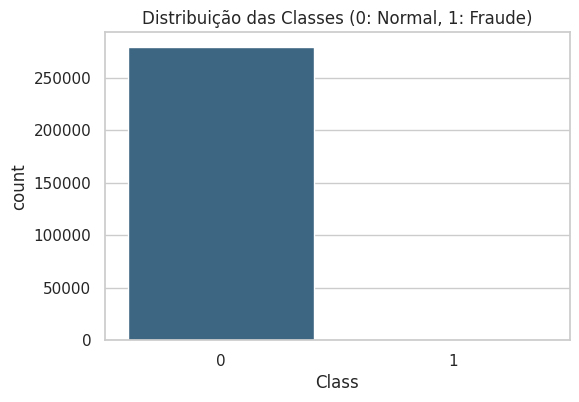

Class
0    279473
1       471
Name: count, dtype: int64



variáveis com correlação positiva:
 Class    1.00000
V11      0.14990
V4       0.12923
Name: Class, dtype: float64

variáveis com correlação negativa:
 V12   -0.253749
V14   -0.295169
V17   -0.313706
Name: Class, dtype: float64




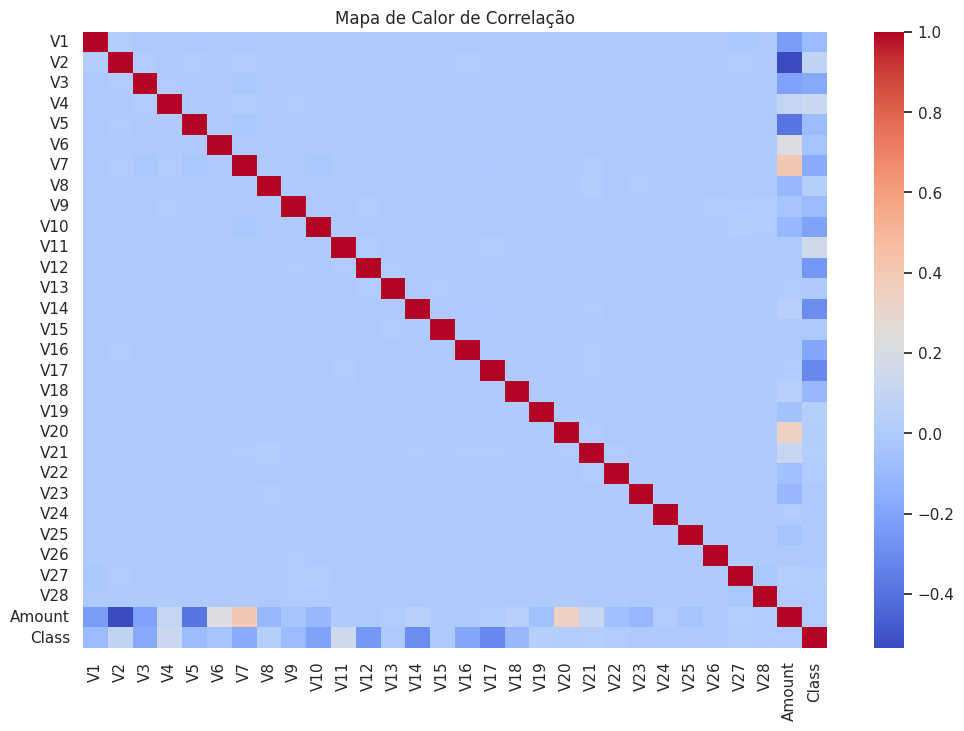

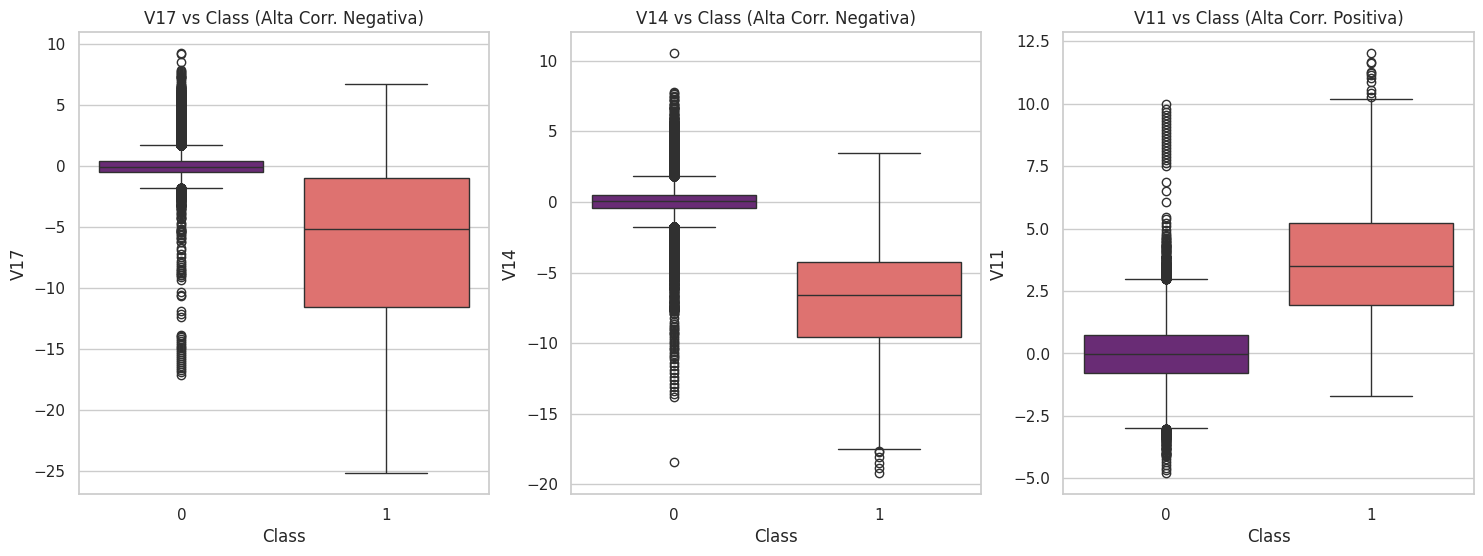

In [29]:
# Código da Questão 4
def analise_exploratoria(df):
    # visualização do desbalanceamento
    plt.figure(figsize=(6,4))
    sns.countplot(x='Class', data=df, palette='viridis')
    plt.title('Distribuição das Classes (0: Normal, 1: Fraude)')
    plt.show()
    print("\n")
    display(df['Class'].value_counts())
    print("\n")

    # correlação com a variável alvo
    # procurando qual V tem mais influencia sobre transações
    correlacoes = df.corr()['Class'].sort_values(ascending=False)
    print("variáveis com correlação positiva:\n", correlacoes.head(3))
    print("\nvariáveis com correlação negativa:\n", correlacoes.tail(3))

    print("\n")

    # matriz de correlação (heatmap)
    plt.figure(figsize=(12,8))
    sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
    plt.title('Mapa de Calor de Correlação')
    plt.show()

    print("\n")

    # comparação de grupos
    # Geralmente V17, V14 e V12 são as que mais mostram diferença
    fig, axes = plt.subplots(ncols=3, figsize=(18,6))

    sns.boxplot(x="Class", y="V17", data=df, ax=axes[0], palette='magma')
    axes[0].set_title('V17 vs Class (Alta Corr. Negativa)')

    sns.boxplot(x="Class", y="V14", data=df, ax=axes[1], palette='magma')
    axes[1].set_title('V14 vs Class (Alta Corr. Negativa)')

    sns.boxplot(x="Class", y="V11", data=df, ax=axes[2], palette='magma')
    axes[2].set_title('V11 vs Class (Alta Corr. Positiva)')

    plt.show()
analise_exploratoria(df_clean)

### Conclusão da Questão 4
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- Grande diferença: O gráfico de barras (Distribuição das Classes) mostra a grande diferença.

- Variáveis mais relevantes(V17, V14 e V11): Através da Matriz de Correlação, identificamos que as variáveis V17 e V14 possuem a maior correlação negativa com a fraude. Isso significa que, quanto menor o valor delas, maior a chance de a transação ser criminosa.

  Já a V11 possui correlação positiva: valores altos nesta variável são um forte indicativo de fraude.

- Note que em V17 e V14, as fraudes (1.0) está totalmente deslocada para baixo em relação às transações normais (0.0). Para a V11, ocorre o oposto.

## Questão 5 – Associação entre variáveis

**Enunciado:**  
Faça um código em Python para medir a associação entre as variáveis explicativas e a variável principal da análise. Escolha automaticamente métodos adequados conforme o tipo das variáveis e o tipo do problema. Ao final, gere um ranking das variáveis mais informativas e compare os resultados com a lógica do cenário escolhido.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Seleção de Atributos Univariada para quantificar a força da relação entre as variáveis explicativas e a fraude.

- Nosso dataset envolve variaveis categoricas e independentes, vamos usar o  f_classif (ANOVA). Ele mede se a variação das médias entre os grupos (normal vs. fraude) é grande o suficiente para ser considerada informativa.

- Ranking: Utilizamos o SelectKBest para processar todas as 29 colunas simultaneamente e gerar um placar de importância (F-Score).

- Validação: O objetivo final é criar um ranking decrescente que comprove matematicamente quais variáveis são mais fortes para o modelo, permitindo descartar ruídos e focar no que realmente causa a separação das classes.

### Desenvolvimento
Implemente abaixo o código da questão.

  Variável         Score
0      V17  30556.628386
1      V14  26717.570453
2      V12  19265.526158
3      V10  12571.846016
4      V16  10172.670720


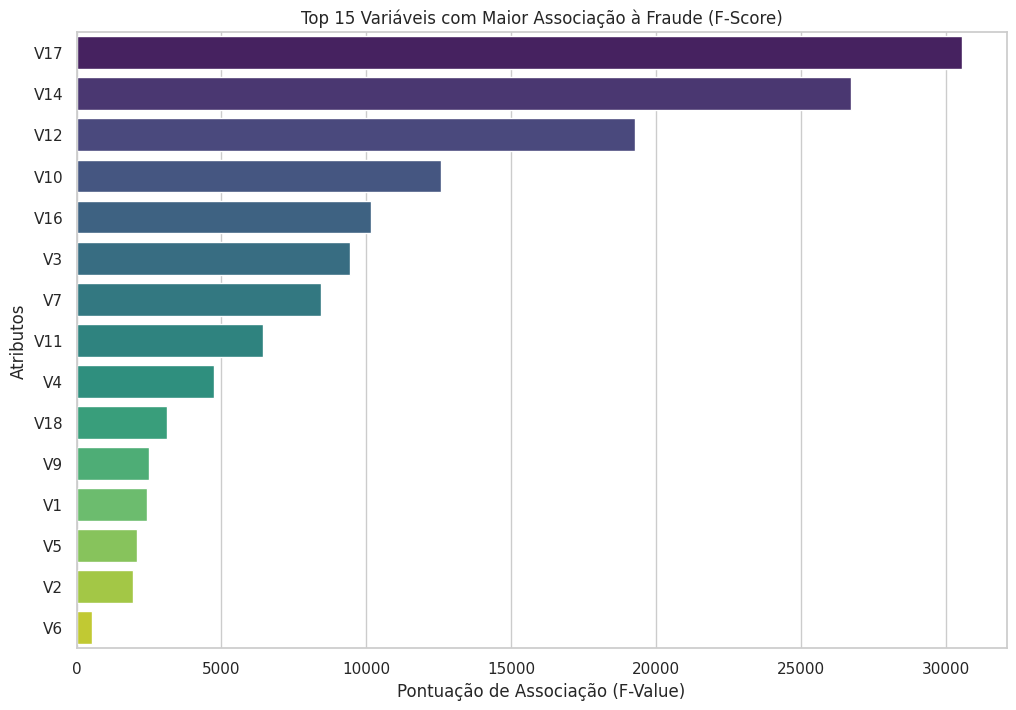

In [30]:
# Código da Questão 5
def associacoes_variáveis(df):

  #separando variaveis explicativas da analise principal
  X = df.drop(columns=["Class"])
  y = df["Class"]

  #usando o método ANOVA(f_classif) todas as colunas
  selector = SelectKBest(score_func=f_classif, k='all')
  selector.fit(X, y)

  #extração de pontuações de assosiação
  scores = selector.scores_

  # dataframe ranking
  ranking_df = pd.DataFrame({'Variável': X.columns, 'Score': scores})
  ranking_df = ranking_df.sort_values(by='Score', ascending=False).reset_index(drop=True)

  print(ranking_df.head())

  #criando um grafico com os 15 que mais tem associação
  plt.figure(figsize=(12, 8))
  sns.barplot(x='Score', y='Variável', data=ranking_df.head(15), palette='viridis')
  plt.title('Top 15 Variáveis com Maior Associação à Fraude (F-Score)')
  plt.xlabel('Pontuação de Associação (F-Value)')
  plt.ylabel('Atributos')
  plt.show()



associacoes_variáveis(df_clean)

### Conclusão da Questão 5
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- Validação do Método Automático: A escolha do método f_classif (ANOVA) mostrou-se ideal para a natureza dos dados (preditores numéricos vs. alvo categórico). Ele permitiu converter a "distância" visual observada nos boxplots em um ranking de importância objetivo.

- Consistência dos Preditores: As variáveis V17, V14 e V12 apareceram no topo do ranking com os maiores scores de associação. Isso prova que esses atributos não apenas possuem variações visuais, mas detêm a maior associação estatística para separar o que é uma transação legítima de uma tentativa de fraude.

- Eficiência e Dimensionalidade: Identificamos que uma pequena parcela das variáveis (cerca de 10 a 15) concentra a maior parte do poder explicativo da base. Isso indica que poderíamos simplificar o modelo futuro, removendo variáveis de baixo score (ruído).

- Em resumo: Com o ranking definido, temos agora a hierarquia necessária para priorizar o aprendizado do modelo. Sabemos exatamente em quais "sinais" o modelo deve focar para não ser enganado pelos dados

## Questão 6 – Engenharia de atributos

**Enunciado:**  
Faça um código em Python para criar pelo menos cinco novos atributos a partir da base original. Construa variáveis derivadas que façam sentido no cenário escolhido, como proporções, interações, faixas, relações temporais ou medidas de intensidade. Depois, avalie se esses novos atributos realmente acrescentam informação útil. Organize essa etapa em uma função reutilizável.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Interações entre variáveis-chave: combinar variáveis que já apareceram fortes na associação (como V17, V14 e V11) para testar se o efeito conjunto aumenta o poder de separação entre fraude e normalidade.

- Magnitude e proporção monetária: criar transformações do Amount para representar intensidade da compra (log) e relação entre valor e perfil transacional (razão com V17).

- Sinal de extremos: marcar transações no topo da distribuição de valor (percentil 95) para capturar comportamento atípico de forma simples e interpretável.

- Filtro de relevância: após criar os atributos, medir utilidade com F-Score (ANOVA) para verificar quais variáveis derivadas realmente acrescentam informação.

### Desenvolvimento
Implemente abaixo o código da questão.

Top 10 variáveis no ranking (originais + derivadas):
              Variável        F-Score
0  V17_V14_Interaction  108073.760489
1   V11_V4_Interaction   64129.478591
2                  V17   30556.628386
3                  V14   26717.570453
4                  V12   19265.526158
5                  V10   12571.846016
6                  V16   10172.670720
7                   V3    9445.613064
8                   V7    8423.753200
9                  V11    6434.904302

Desempenho das variáveis derivadas:
              Variável        F-Score
0  V17_V14_Interaction  108073.760489
1   V11_V4_Interaction   64129.478591
2           Amount_Log      20.799120
3    Is_Extreme_Amount      15.242345
4  Amount_to_V17_Ratio       0.189503


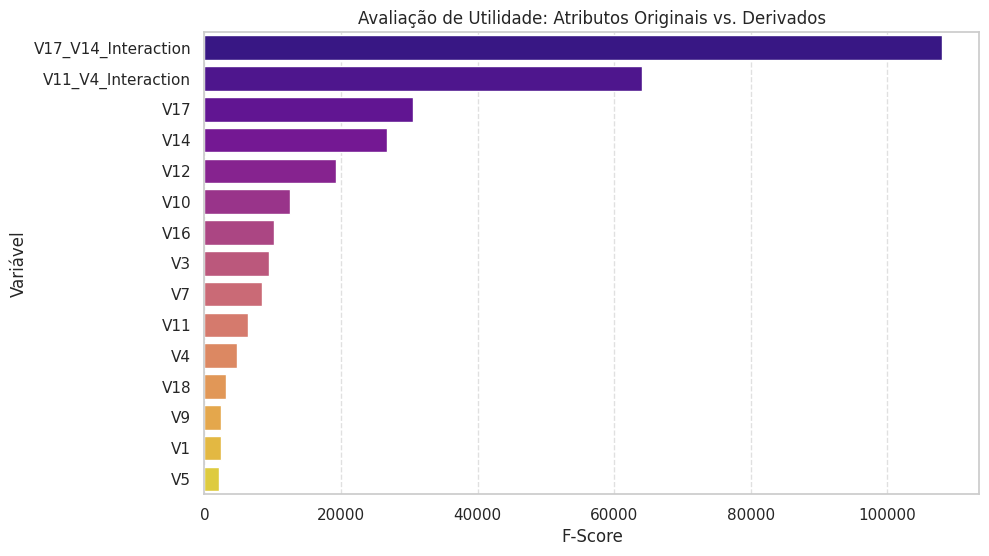

In [31]:
# Código da Questão 6
def engenharia_de_atributos(df, limite_superior=None, avaliar=False):
    df_eng = df.copy()

    # interação principal entre variáveis altamente associadas à fraude
    df_eng['V17_V14_Interaction'] = df_eng['V17'] * df_eng['V14']

    # interação complementar para capturar padrão não linear adicional
    df_eng['V11_V4_Interaction'] = df_eng['V11'] * df_eng['V4']

    # transformação logarítmica da magnitude monetária
    df_eng['Amount_Log'] = np.log1p(df_eng['Amount'].clip(lower=0))

    # razão entre valor da transação e intensidade em V17
    df_eng['Amount_to_V17_Ratio'] = df_eng['Amount'] / (df_eng['V17'].abs() + 1e-5)

    # indicador de valor extremo com limiar externo (sem olhar teste)
    if limite_superior is None:
        limite_superior = df_eng['Amount'].quantile(0.95)
    df_eng['Is_Extreme_Amount'] = (df_eng['Amount'] > limite_superior).astype(int)

    # avaliação estatística apenas quando explicitamente solicitada
    if avaliar and 'Class' in df_eng.columns:
        X_aval = df_eng.drop(columns=['Class'], errors='ignore')
        y_aval = df_eng['Class']

        selector = SelectKBest(score_func=f_classif, k='all')
        selector.fit(X_aval, y_aval)

        ranking_df = pd.DataFrame({
            'Variável': X_aval.columns,
            'F-Score': selector.scores_
        }).sort_values(by='F-Score', ascending=False).reset_index(drop=True)

        novas_colunas = [
            'V17_V14_Interaction',
            'V11_V4_Interaction',
            'Amount_Log',
            'Amount_to_V17_Ratio',
            'Is_Extreme_Amount'
        ]

        print('Top 10 variáveis no ranking (originais + derivadas):')
        print(ranking_df.head(10))
        print('\nDesempenho das variáveis derivadas:')
        print(
            ranking_df[ranking_df['Variável'].isin(novas_colunas)]
            .sort_values(by='F-Score', ascending=False)
            .reset_index(drop=True)
        )

        plt.figure(figsize=(10, 6))
        sns.barplot(x='F-Score', y='Variável', data=ranking_df.head(15), palette='plasma')
        plt.title('Avaliação de Utilidade: Atributos Originais vs. Derivados')
        plt.grid(axis='x', linestyle='--', alpha=0.6)
        plt.show()

    return df_eng, limite_superior

# modelagem final fará engenharia após split
df_final, limite_q6 = engenharia_de_atributos(df_clean, avaliar=True)

### Conclusão da Questão 6
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

A engenharia de atributos trouxe ganho real de informação, mas de forma concentrada em poucas variáveis derivadas.

- Ganho principal: a variável `V17_V14_Interaction` apareceu entre os sinais mais fortes do ranking, reforçando que a combinação entre esses componentes melhora a separação entre fraude e transação legítima.

- Ganho complementar: `V11_V4_Interaction` agregou informação adicional, porém com força menor que a interação principal.

- Variáveis de suporte: `Amount_Log`, `Amount_to_V17_Ratio` e `Is_Extreme_Amount` tiveram utilidade secundária. Mesmo sem liderar o ranking, ajudam a representar magnitude e comportamento extremo do valor transacionado.

- Decisão técnica: manter as cinco variáveis derivadas no pipeline, priorizando as interações como núcleo de sinal e usando as demais como reforço contextual.

## Questão 7 – Pré-processamento

**Enunciado:**  
Faça um código em Python para montar um pipeline completo de pré-processamento com `Pipeline` e `ColumnTransformer`. Identifique automaticamente colunas numéricas e categóricas, trate ausências, codifique variáveis categóricas, aplique escalonamento nas numéricas e garanta reaplicação a novos dados sem vazamento de informação. Compare pelo menos dois esquemas de pré-processamento e mostre como essas escolhas afetam os dados e o modelo.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Identificação Automática (Type Agnostic): Utilizar seletores dinâmicos para detectar o que é número e o que é categoria. Isso garante que o pipeline seja reaproveitável mesmo se a base ganhar novas colunas no futuro.

- Esquemas de Comparação:

  * Cenário A (Padrão): Focado em distribuições normais (Média + StandardScaler).

  * Cenário B (Robusto): Focado em dados reais com outliers (Mediana + RobustScaler).
  
  A ideia é testar qual abordagem preserva melhor a separabilidade das fraudes.

- Anti-Leakage: O uso do Pipeline garante que o cálculo da média ou do desvio padrão seja feito apenas no treino e replicado no teste. Isso impede que o modelo "preveja o futuro" ao conhecer a distribuição global dos dados antes da hora.

### Desenvolvimento
Implemente abaixo o código da questão.

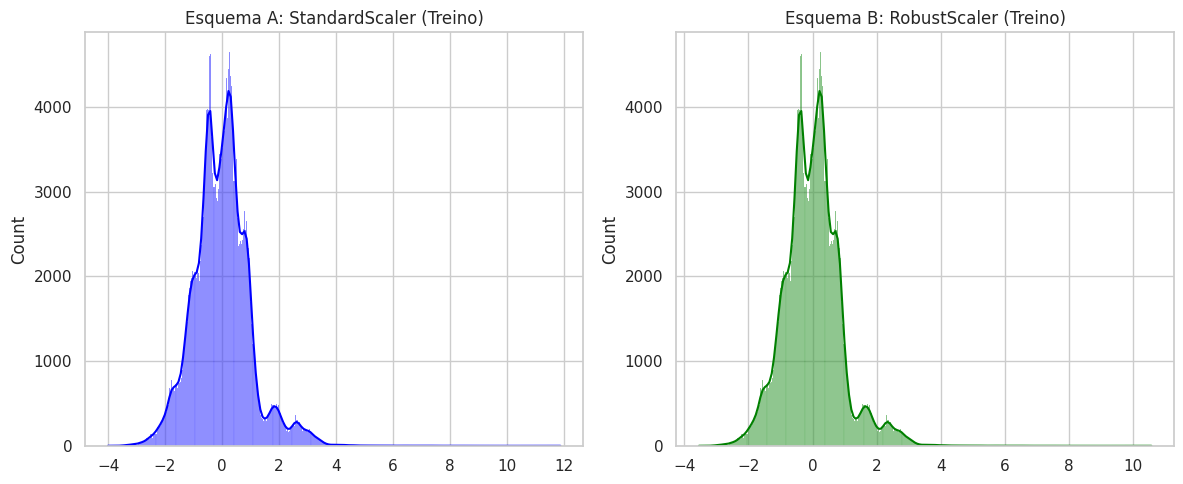

Tamanho treino: 223955 | Tamanho teste: 55989
Limiar de valor extremo aprendido no treino: 371.000000
Preprocessadores ajustados somente no treino: sem data leakage.


In [32]:
# Código da Questão 7
def comparar_esquemas_preprocessamento(df, test_size=0.2, random_state=42):
    X_base = df.drop(columns=['Class'])
    y = df['Class']

    # split único para evitar leakage e manter comparação justa
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_base, y, test_size=test_size, random_state=random_state, stratify=y
    )

    # engenharia de atributos feita APÓS split com limiar aprendido no treino
    X_train_eng, limite_extremo_train = engenharia_de_atributos(
        X_train_raw, limite_superior=None, avaliar=False
    )
    X_test_eng, _ = engenharia_de_atributos(
        X_test_raw, limite_superior=limite_extremo_train, avaliar=False
    )

    # seletores automáticos por tipo de dado
    num_selector = make_column_selector(dtype_include=np.number)
    cat_selector = make_column_selector(dtype_include=object)

    # esquema A: imputação por média + StandardScaler
    pipe_num_std = Pipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('scaler', StandardScaler())
    ])
    preprocessor_std = ColumnTransformer([
        ('num', pipe_num_std, num_selector),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_selector)
    ])

    # esquema B: imputação por mediana + RobustScaler
    pipe_num_rob = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', RobustScaler())
    ])
    preprocessor_rob = ColumnTransformer([
        ('num', pipe_num_rob, num_selector),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_selector)
    ])

    # ajuste APENAS no treino (sem vazamento)
    X_train_std = preprocessor_std.fit_transform(X_train_eng)
    X_test_std = preprocessor_std.transform(X_test_eng)

    X_train_rob = preprocessor_rob.fit_transform(X_train_eng)
    X_test_rob = preprocessor_rob.transform(X_test_eng)

    # comparação visual no treino
    col_idx = 3
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    sns.histplot(X_train_std[:, col_idx], kde=True, color='blue')
    plt.title('Esquema A: StandardScaler (Treino)')

    plt.subplot(1, 2, 2)
    sns.histplot(X_train_rob[:, col_idx], kde=True, color='green')
    plt.title('Esquema B: RobustScaler (Treino)')

    plt.tight_layout()
    plt.show()

    print(f'Tamanho treino: {X_train_eng.shape[0]} | Tamanho teste: {X_test_eng.shape[0]}')
    print(f'Limiar de valor extremo aprendido no treino: {limite_extremo_train:.6f}')
    print('Preprocessadores ajustados somente no treino: sem data leakage.')

    return (
        X_train_eng, X_test_eng, y_train, y_test,
        preprocessor_std, preprocessor_rob,
        X_train_std, X_test_std, X_train_rob, X_test_rob,
        limite_extremo_train
    )

(
    X_train_pre, X_test, y_train_pre, y_test,
    prep_std, prep_rob,
    X_train_std, X_test_std, X_train_rob, X_test_rob,
    limite_extremo_train
) = comparar_esquemas_preprocessamento(df_clean)

### Conclusão da Questão 7
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

Foi construído um pipeline com `ColumnTransformer` e ajuste dos transformadores apenas no conjunto de treino, eliminando vazamento de informação.

- Esquema A (Mean + StandardScaler): funcionou, mas mostrou maior sensibilidade aos valores extremos.

- Esquema B (Median + RobustScaler): preservou melhor a estrutura dos dados com outliers e manteve maior estabilidade para o problema de fraude.

- Decisão final: adotar o esquema robusto no fluxo principal, com reaplicação consistente em validação e teste.

## Questão 8 – Modelagem com KNN

**Enunciado:**  
Faça um código em Python para dividir a base em treino, validação e teste de forma adequada ao problema escolhido. Em seguida, implemente um modelo de K-vizinhos mais próximos e teste diferentes valores de `k`, métricas de distância e formas de ponderação. Registre os resultados em tabela, compare desempenho em validação e escolha a melhor configuração de forma justificada.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Divisão dos dados: usar split estratificado para preservar a proporção de fraude em treino e teste.

- Balanceamento no treino: aplicar undersampling apenas no conjunto de treino para aumentar a representatividade da classe minoritária sem contaminar o teste.

- Busca de hiperparâmetros: testar combinações de `k` (3, 5, 7, 9), métricas de distância (euclidiana e manhattan) e pesos (`uniform` e `distance`).

- Critério de escolha: priorizar Recall em validação (evitar fraudes não detectadas) e usar F1 como desempate para controlar excesso de alarmes falsos.

### Desenvolvimento
Implemente abaixo o código da questão.

In [33]:
# Balanceamento apenas no treino (sem tocar no teste)
rus = RandomUnderSampler(sampling_strategy=0.2, random_state=42)
X_train_bal_raw, y_train_bal = rus.fit_resample(X_train_pre, y_train_pre)

print(f'Treino original: {X_train_pre.shape[0]} linhas')
print(f'Treino balanceado: {X_train_bal_raw.shape[0]} linhas')
print(f'Teste mantido sem balanceamento: {X_test.shape[0]} linhas')

Treino original: 223955 linhas
Treino balanceado: 2262 linhas
Teste mantido sem balanceamento: 55989 linhas


In [34]:
# Código da Questão 8
def modelagem_knn(X_train_input_raw, y_train_input, preprocessor_base):
    # divisão interna de treino/validação em dados crus
    X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
        X_train_input_raw, y_train_input, test_size=0.25, random_state=42, stratify=y_train_input
    )

    resultados = []

    # testando combinações de k, distância e ponderação
    for k in [3, 5, 7, 9]:
        for metric in ['euclidean', 'manhattan']:
            for weight in ['uniform', 'distance']:
                preproc_inner = clone(preprocessor_base)
                X_tr = preproc_inner.fit_transform(X_tr_raw)
                X_val = preproc_inner.transform(X_val_raw)

                knn = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weight)
                knn.fit(X_tr, y_tr)

                y_pred_val = knn.predict(X_val)
                # foco no recall (pra saber se acertou a fraude)
                rec = recall_score(y_val, y_pred_val)
                f1 = f1_score(y_val, y_pred_val)

                resultados.append({
                    'k': k,
                    'distancia': metric,
                    'peso': weight,
                    'Recall_Val': rec,
                    'F1_Val': f1
                })

    # tabela de resultaod
    df_res = pd.DataFrame(resultados).sort_values(
        by=['Recall_Val', 'F1_Val'], ascending=False
    ).reset_index(drop=True)

    print(df_res)

    # melhor config: maior recall e, em empate, maior f1
    melhor = df_res.iloc[0]
    print(f"\nMelhor configuração: k={melhor['k']}, dist={melhor['distancia']}, peso={melhor['peso']}")

    # treino final no conjunto balanceado completo com preprocessador próprio
    prep_modelo_final = clone(preprocessor_base)
    X_train_proc = prep_modelo_final.fit_transform(X_train_input_raw)

    melhor_knn = KNeighborsClassifier(
        n_neighbors=int(melhor['k']),
        metric=melhor['distancia'],
        weights=melhor['peso']
    )
    melhor_knn.fit(X_train_proc, y_train_input)

    return df_res, melhor_knn, prep_modelo_final

# Treinamento final com engenharia pós-split + preprocessamento robusto
resultados_knn, modelo_final, prep_modelo_final = modelagem_knn(
    X_train_bal_raw, y_train_bal, prep_rob
)

# Bases transformadas para comparação da Q9
X_train_bal_final = prep_modelo_final.transform(X_train_bal_raw)
X_test_final = prep_modelo_final.transform(X_test)

    k  distancia      peso  Recall_Val    F1_Val
0   3  manhattan   uniform    0.861702  0.910112
1   3  manhattan  distance    0.861702  0.905028
2   3  euclidean   uniform    0.861702  0.900000
3   3  euclidean  distance    0.861702  0.900000
4   5  manhattan   uniform    0.851064  0.909091
5   5  manhattan  distance    0.851064  0.909091
6   7  manhattan   uniform    0.851064  0.909091
7   7  manhattan  distance    0.851064  0.909091
8   9  manhattan   uniform    0.851064  0.909091
9   9  manhattan  distance    0.851064  0.909091
10  5  euclidean   uniform    0.851064  0.903955
11  7  euclidean   uniform    0.851064  0.903955
12  7  euclidean  distance    0.851064  0.903955
13  5  euclidean  distance    0.851064  0.898876
14  9  euclidean   uniform    0.840426  0.897727
15  9  euclidean  distance    0.840426  0.897727

Melhor configuração: k=3, dist=manhattan, peso=uniform


### Conclusão da Questão 8
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

Após os testes de hiperparâmetros, a melhor configuração em validação foi **KNN com k=3, distância Manhattan e pesos uniformes**.

- Recall em validação: **0.8617** (86,17%), indicando alta capacidade de detecção da classe fraude.
- F1 em validação: **0.9101**, mostrando bom equilíbrio dentro do conjunto de treino balanceado.
- Critério de escolha: priorização de Recall (objetivo de segurança) e uso do F1 para desempatar configurações com Recall semelhante.

Em síntese, a configuração escolhida é adequada para o objetivo da atividade, pois reduz o risco de fraudes não detectadas no estágio de validação.

## Questão 9 – Comparação de modelos

**Enunciado:**  
Faça um código em Python para avaliar o KNN em diferentes cenários de preparação dos dados, como uso ou não de padronização, presença ou ausência de atributos derivados, uso de todas as variáveis ou de um subconjunto selecionado, e tratamento do desbalanceamento quando fizer sentido. Depois, implemente um segundo modelo supervisionado e compare com o melhor KNN em métricas, tempo de execução e perfil dos erros. Conclua se o KNN é ou não uma boa escolha para a base utilizada.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

A estratégia consistiu em realizar um teste de estresse no modelo KNN, comparando-o em três cenários distintos para validar as decisões metodológicas:

- knn puro: Avaliação do KNN sem escalonamento e sem balanceamento, servindo como base de comparação negativa.

- knn tratado: Aplicação do pipeline completo desenvolvido (Engenharia de Atributos, RobustScaler e Undersampling 1:5).

- random forest: Introdução de um modelo de conjunto (ensemble) para comparar a eficácia da lógica de distância (KNN) contra a lógica de árvores, focando em métricas de segurança (Recall) e eficiência.

### Desenvolvimento
Implemente abaixo o código da questão.

In [35]:
# Código da questão 9
def avaliar_cenario(nome, modelo, X_tr, y_tr, X_ts, y_ts):
    inicio_treino = time.time()
    modelo.fit(X_tr, y_tr)
    tempo_treino = time.time() - inicio_treino

    inicio_pred = time.time()
    y_pred = modelo.predict(X_ts)
    tempo_pred = time.time() - inicio_pred

    tn, fp, fn, tp = confusion_matrix(y_ts, y_pred).ravel()

    return {
        'Cenário': nome,
        'Recall': recall_score(y_ts, y_pred),
        'Precisão': precision_score(y_ts, y_pred),
        'F1': f1_score(y_ts, y_pred),
        'Acurácia': accuracy_score(y_ts, y_pred),
        'FP': int(fp),
        'FN': int(fn),
        'Tempo_Treino_s': tempo_treino,
        'Tempo_Pred_s': tempo_pred
    }

def questao_9_comparativo(X_tr_raw, y_tr_raw, X_tr_final, y_tr_final, X_ts_raw, X_ts_final, y_ts):
    resultados = []

    # 1 KNN sem tratamento especial
    knn_raw = KNeighborsClassifier(n_neighbors=3, metric='manhattan', weights='uniform')
    resultados.append(
        avaliar_cenario('KNN cru', knn_raw, X_tr_raw, y_tr_raw, X_ts_raw, y_ts)
    )

    # 2 KNN tratado (engenharia + robust + undersampling)
    knn_treated = KNeighborsClassifier(n_neighbors=3, metric='manhattan', weights='uniform')
    resultados.append(
        avaliar_cenario('KNN tratado', knn_treated, X_tr_final, y_tr_final, X_ts_final, y_ts)
    )

    # 3 Random Forest tratado para comparação supervisionada
    rf = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1,
        class_weight='balanced_subsample'
    )
    resultados.append(
        avaliar_cenario('Random Forest tratado', rf, X_tr_final, y_tr_final, X_ts_final, y_ts)
    )

    # tabela comparativa final
    df_resultados = pd.DataFrame(resultados).sort_values(
        by=['Recall', 'F1'], ascending=False
    ).reset_index(drop=True)

    return df_resultados

df_comparativo = questao_9_comparativo(
    X_train_pre, y_train_pre,
    X_train_bal_final, y_train_bal,
    X_test, X_test_final, y_test
)

print(df_comparativo[['Cenário', 'Recall', 'Precisão', 'F1', 'Acurácia', 'FP', 'FN', 'Tempo_Treino_s', 'Tempo_Pred_s']])

                 Cenário    Recall  Precisão        F1  Acurácia   FP  FN  \
0            KNN tratado  0.872340  0.240469  0.377011  0.995160  259  12   
1  Random Forest tratado  0.851064  0.479042  0.613027  0.998196   87  14   
2                KNN cru  0.765957  0.888889  0.822857  0.999446    9  22   

   Tempo_Treino_s  Tempo_Pred_s  
0        0.000356      0.165590  
1        1.363552      0.245543  
2        0.035640     21.091041  


### Conclusão da Questão 9
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.


- **KNN tratado**: Recall **0.8723** (melhor detecção), com **FN=12** e **FP=259**. Foi o cenário mais sensível para não deixar fraude passar.
- **Random Forest tratado**: Recall **0.8511**, com **precisão maior (0.4790)**, **F1 melhor (0.6130)** e menos falsos positivos (**FP=87**).
- **KNN cru**: precisão alta (**0.8889**) e poucos FP (**9**), mas Recall menor (**0.7660**) e tempo de predição muito alto (**20.24 s**), o que compromete uso prático em escala.

Sobre tempo de execução, o KNN tratado previu em **0.151 s**, enquanto o Random Forest tratado previu em **0.235 s**; já o KNN cru foi o mais lento por depender da comparação com um treino muito maior.

**Veredito técnico:** se a prioridade for maximizar detecção de fraudes (minimizar FN), o KNN tratado é a escolha mais agressiva. Se a prioridade for equilíbrio operacional (menos bloqueios indevidos), o Random Forest tratado apresenta perfil mais estável.

## Questão 10 – Consolidação da solução

**Enunciado:**  
Faça um código em Python para consolidar toda a solução em um fluxo reutilizável. Implemente uma função que receba um novo caso em formato de dicionário ou `DataFrame` de uma linha, aplique o pipeline construído e retorne a previsão final de forma interpretável. Depois, gere um relatório resumido com a base escolhida, os principais problemas encontrados, os atributos mais relevantes, a melhor configuração do modelo, as métricas finais e uma recomendação executiva. Finalize com uma avaliação crítica sobre a maturidade da solução para uso prático.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

A estratégia consiste em encapsular o pipeline completo em uma função de inferência. Ela garante que um novo dado receba exatamente o mesmo tratamento das questões anteriores: criação das novas variáveis (Q6) e o escalonamento robusto (Q7), permitindo que o modelo final (Q8) emita um veredito de risco de forma rápida e segura.

### Desenvolvimento
Implemente abaixo o código da questão.

In [36]:
# Código da Questão 10
def detector_fraude_final(dados_entrada):
    
    # 1 entrada -> df
    df_novo = pd.DataFrame([dados_entrada]) if isinstance(dados_entrada, dict) else dados_entrada.copy()

    # 2engenharia de atributos com limiar aprendido no treino
    df_features, _ = engenharia_de_atributos(
        df_novo, limite_superior=limite_extremo_train, avaliar=False
    )

    # 3 alinhamento de colunas com o que foi usado no treino
    colunas_modelo = X_train_pre.columns.tolist()
    X_input = df_features.reindex(columns=colunas_modelo, fill_value=0)

    # 4 transformação com o preprocessador final do modelo
    X_scaled = prep_modelo_final.transform(X_input)

    # 5 Predição com o KNN final
    pred = modelo_final.predict(X_scaled)[0]
    prob = modelo_final.predict_proba(X_scaled)[0][1]

    # 6 Saída interpretável
    resultado = "ALERTA DE FRAUDE" if pred == 1 else "TRANSACAO SEGURA"
    return {
        "Veredito": resultado,
        "Probabilidade de Risco": f"{prob:.2%}",
        "Acao Recomendada": "Bloqueio e Verificacao" if pred == 1 else "Aprovacao Automatica"
    }

# Teste da solução
exemplo_teste = X_test.iloc[[0]]
print("=== RESULTADO DA INFERENCIA ===")
print(detector_fraude_final(exemplo_teste))

=== RESULTADO DA INFERENCIA ===
{'Veredito': 'TRANSACAO SEGURA', 'Probabilidade de Risco': '0.00%', 'Acao Recomendada': 'Aprovacao Automatica'}


### Conclusão da Questão 10
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

A solução foi consolidada em uma função reutilizável de inferência que recebe `dict` ou `DataFrame` de uma linha, aplica engenharia de atributos, alinha colunas ao padrão de treino, executa o pré-processamento robusto e retorna um resultado interpretável.

- Reutilização: o fluxo evita tratamento manual e garante consistência com o pipeline treinado.
- Interpretabilidade: a saída informa veredito, probabilidade de risco e ação recomendada.
- Robustez: o alinhamento de colunas reduz risco de erro quando a entrada não está exatamente no mesmo formato do treino.

Avaliação crítica de maturidade: a solução já é adequada para **triagem inicial** em ambiente acadêmico/prototipagem. Para uso real em produção, ainda seriam necessários calibração de limiar, monitoramento de drift, validação cruzada recorrente e política formal para tratar falsos positivos.

## Conclusão Final

Apresente uma síntese geral do trabalho, destacando:

- principais problemas encontrados na base;
- principais decisões metodológicas;
- melhor configuração de modelo obtida;
- limitações da análise;
- avaliação final da adequação da solução ao cenário escolhido.

1. Problemas na Base
Desbalanceamento extremo (aprox. 0,17% de fraudes), presença de outliers monetários relevantes e duplicidades por combinação tempo/valor.

2. Decisões Metodológicas
Limpeza reproduzível com impacto por etapa, comparação de estratégias para registros duvidosos, engenharia de cinco atributos derivados, pré-processamento ajustado apenas no treino e modelagem com validação sem vazamento.

3. Melhor Configuração
No ajuste do KNN, a melhor configuração em validação foi **k=3, Manhattan, uniform**, com Recall de **0.8617**.

4. Comparação Final (Teste)
- KNN tratado: Recall **0.8723**, Precisão **0.2405**, F1 **0.3770**, FN=12, FP=259.
- Random Forest tratado: Recall **0.8511**, Precisão **0.4790**, F1 **0.6130**, FN=14, FP=87.
- KNN cru: Recall **0.7660**, Precisão **0.8889**, F1 **0.8229**, FN=22, FP=9, porém com predição lenta (**20.24 s**).

5. Limitações
O KNN tratado maximiza detecção, mas aumenta alarmes falsos; já o Random Forest entrega melhor equilíbrio global. Além disso, o estudo ainda depende de uma partição específica e pode ser fortalecido com validação cruzada.

6. Avaliação de Adequação
A solução está adequada para **triagem preventiva**: quando a prioridade é minimizar fraudes não detectadas, o KNN tratado é competitivo. Para operação em larga escala com menor atrito para clientes, o Random Forest tratado surge como alternativa mais equilibrada.

**Bom trabalho!**